# 05 — Explainability (bonus)

What do the models rely on? (1) top TF-IDF n-grams per class from the baseline coefficients; (2) **token attributions** of the fine-tuned encoder (Integrated Gradients, Captum), on single examples and aggregated over many texts; (3) **SHAP** values of the stacking model (which signals the final model uses, especially for fusion).

**Run on Kaggle**
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. *Settings*: Accelerator **GPU T4 x2**, Internet **On** (downloads Hugging Face weights).
3. *Add Input*: competition **ai-generated-text-detection-hw3-ucu-ai-2026**, and the outputs of **02_baseline**, **03b_encoder_full** (or **03_encoder**), **04b_my_approach_v2** (or **04_my_approach**).
4. *Save Version → Save & Run All (Commit)*. **ETA: ~20–30 min.**

**Copy back into the repo** (from the version's *Output* tab):
- this notebook with outputs → `notebooks/05_explainability.ipynb`
- `xai_*.png` → `reports/figures/`


In [1]:
import os, glob, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SMOKE = bool(os.environ.get('SMOKE'))  # tiny local dry-run of the whole notebook; never set on Kaggle
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT.mkdir(exist_ok=True)
SEED, LABELS = 42, ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    """Locate an input file in attached Kaggle inputs (or ../data locally)."""
    for root in ['/kaggle/input', '../data', str(OUT)]:
        hits = sorted(glob.glob(f'{root}/**/{name}', recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found: attach the inputs listed at the top of this notebook')

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")  # the competition metric

def report(y_true, y_pred, title):
    """Per-class metrics + normalized confusion matrix (labels are class indices)."""
    print(f'{title}: macro-F1 = {macro_f1(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', values_format='.3f')
    plt.title(title); plt.grid(False)
    plt.savefig(OUT / f"cm_{re.sub(r'[^a-z0-9]+', '_', title.lower())}.png", dpi=120, bbox_inches='tight'); plt.show()

def f1_by(df, pred_col, by):
    return df.groupby(by).apply(lambda d: macro_f1(d.y, d[pred_col])).round(4).rename('macro_f1').to_frame().join(df[by].value_counts().rename('n'))

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
if SMOKE:
    test = test.head(300); sub = sub[sub.id.isin(test.id)]
train['y'] = train.label.map(L2I)
print(train.shape, test.shape)

(272352, 6) (25000, 4)


In [2]:
split = pd.read_csv(find('split.csv'))
train = train.merge(split, on='id', validate='1:1')
val = train[train.is_val].reset_index(drop=True)
print('val rows:', len(val), '| fixed train sample:', (train.sample_rank >= 0).sum())

val rows: 27451 | fixed train sample: 60001


## 1. Baseline: most class-indicative n-grams

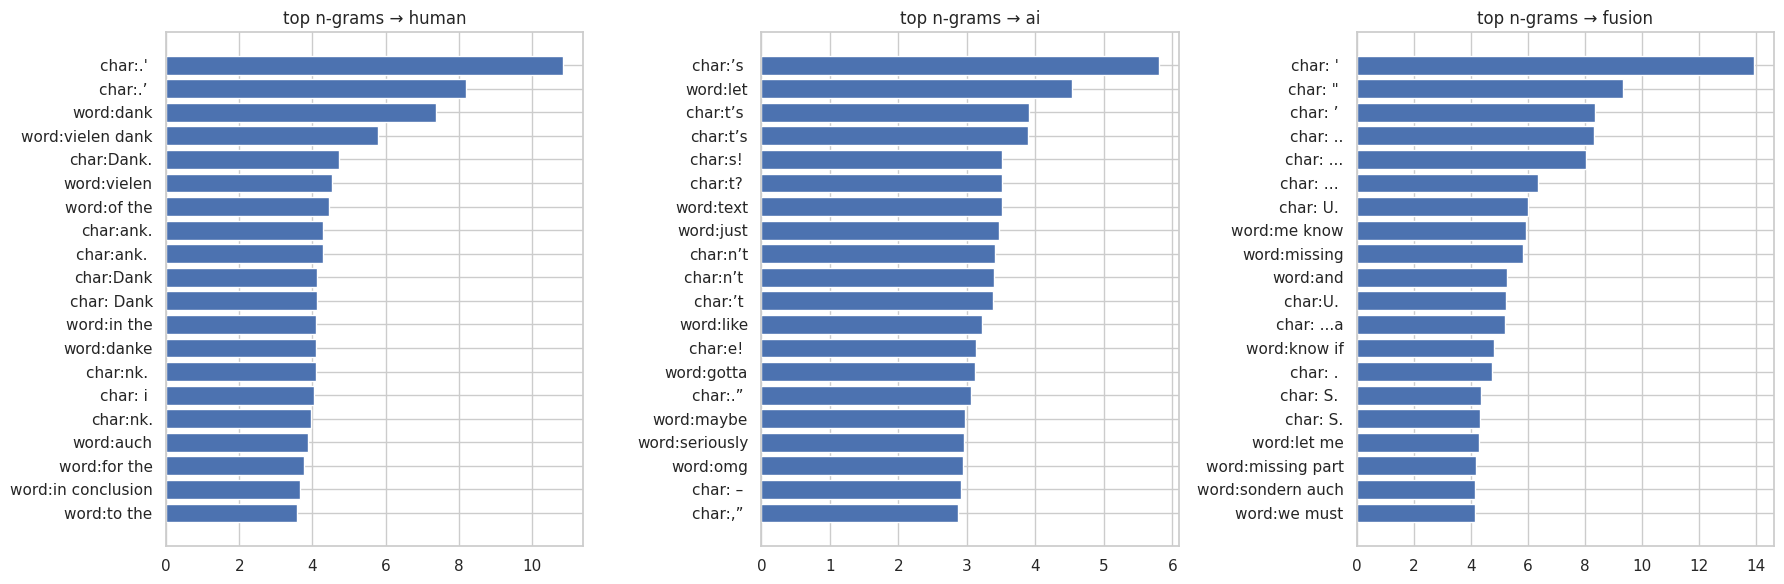

In [3]:
import joblib
b = joblib.load(find('baseline.joblib'))
names = np.concatenate([[f'{n}:{t}' for t in b['vecs'][n].get_feature_names_out()] for n in b['features'].split('+')])
clf = b['clf']
coef = clf.coef_ if hasattr(clf, 'coef_') else clf.feature_log_prob_ - clf.feature_log_prob_.mean(0)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for k, ax in enumerate(axes):
    top = np.argsort(coef[k])[-20:]
    ax.barh(names[top], coef[k][top]); ax.set_title(f'top n-grams → {LABELS[k]}')
plt.tight_layout(); plt.savefig(OUT / 'xai_baseline_ngrams.png', dpi=120); plt.show()

## 2. Encoder: Integrated Gradients token attributions

In [4]:
import torch
try:
    from captum.attr import LayerIntegratedGradients
except ImportError:
    os.system('pip install -q captum'); from captum.attr import LayerIntegratedGradients
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from IPython.display import HTML, display

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
try:
    enc_dir = str(Path(find('encoder_full_model/config.json')).parent)  # prefer the full-data encoder (03b)
except FileNotFoundError:
    enc_dir = str(Path(find('encoder_model/config.json')).parent)
print('explaining', enc_dir)
tok = AutoTokenizer.from_pretrained(enc_dir)
model = AutoModelForSequenceClassification.from_pretrained(enc_dir, dtype=torch.float32).to(DEV).eval()
lig = LayerIntegratedGradients(lambda ids, mask: model(input_ids=ids, attention_mask=mask).logits, model.base_model.embeddings)
XAI_LEN = 256

def attribute(text, target):
    ids = tok(text, truncation=True, max_length=XAI_LEN, return_tensors='pt').input_ids.to(DEV)
    mask = torch.ones_like(ids)
    base = torch.full_like(ids, tok.pad_token_id); base[0, 0], base[0, -1] = ids[0, 0], ids[0, -1]
    a = lig.attribute(ids, base, additional_forward_args=(mask,), target=int(target), n_steps=32, internal_batch_size=16).sum(-1)[0]
    with torch.no_grad():
        prob = model(input_ids=ids, attention_mask=mask).logits.softmax(-1)[0].cpu().numpy()
    return tok.convert_ids_to_tokens(ids[0]), (a / a.abs().max()).detach().cpu().numpy(), prob

def show(tokens, attr, title):
    spans = ''.join(f'<span style="background:rgba({"220,40,40" if v > 0 else "40,90,220"},{abs(v):.2f})">{t.replace("▁", " ")}</span>' for t, v in zip(tokens, attr))
    display(HTML(f'<b>{title}</b><div style="line-height:1.8">{spans}</div><br>'))

explaining /kaggle/input/notebooks/vivtrea/encoder-3x/encoder_full_model


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

In [5]:
# red = pushes towards the true class, blue = against; one random val example per class
sample = pd.concat([val[val.label == l].sample(1, random_state=SEED) for l in LABELS])
for _, r in sample.iterrows():
    toks, a, p = attribute(r.text, r.y)
    show(toks, a, f'{r.label} ({r.lang}/{r.domain}), p = {dict(zip(LABELS, p.round(3)))}')

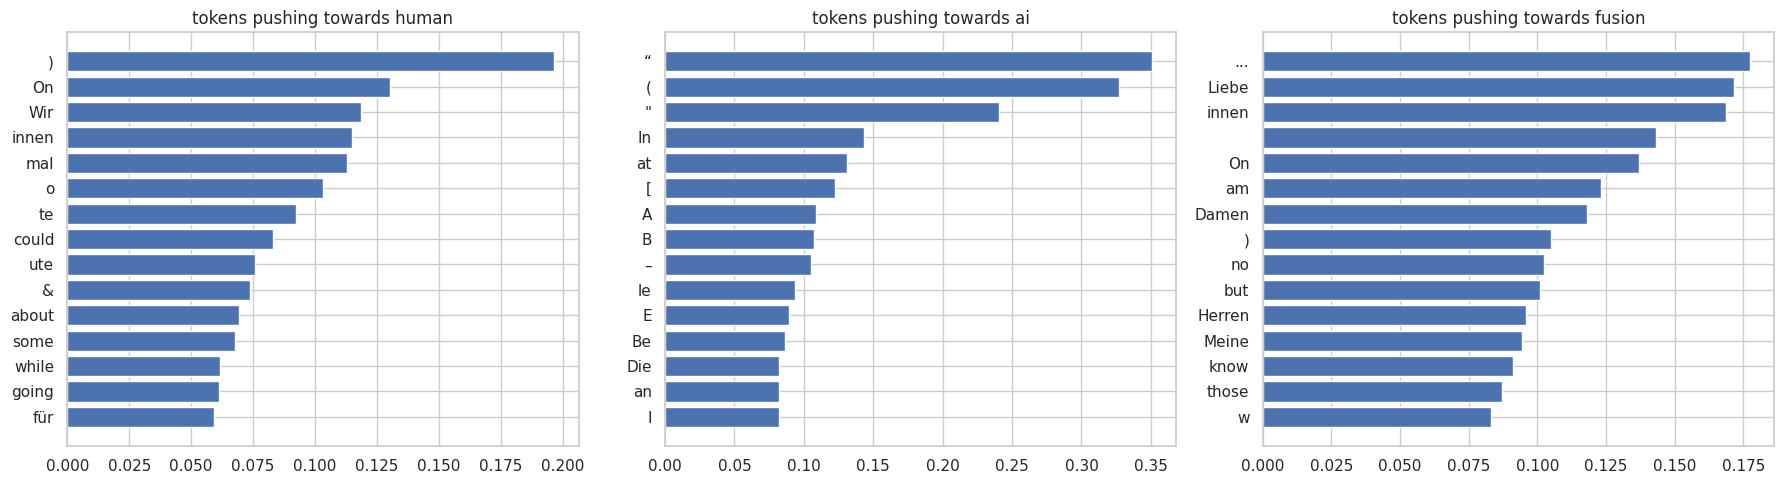

In [6]:
# aggregate: mean attribution of each token towards the true class over N texts per class
N_AGG = 3 if SMOKE else 60
agg = []
for l in LABELS:
    for _, r in val[val.label == l].sample(N_AGG, random_state=SEED).iterrows():
        toks, a, _ = attribute(r.text, r.y)
        agg += [{'label': l, 'token': t.replace('▁', ''), 'attr': v} for t, v in zip(toks[1:-1], a[1:-1])]
agg = pd.DataFrame(agg)
tops = (agg.groupby(['label', 'token']).attr.agg(['mean', 'count']).query('count >= 8' if not SMOKE else 'count >= 1')
        .sort_values('mean', ascending=False).groupby(level=0).head(15).reset_index())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, l in zip(axes, LABELS):
    d = tops[tops.label == l].iloc[::-1]
    ax.barh(d.token, d['mean']); ax.set_title(f'tokens pushing towards {l}')
plt.tight_layout(); plt.savefig(OUT / 'xai_encoder_tokens.png', dpi=120); plt.show()

## 3. Stacking model: SHAP

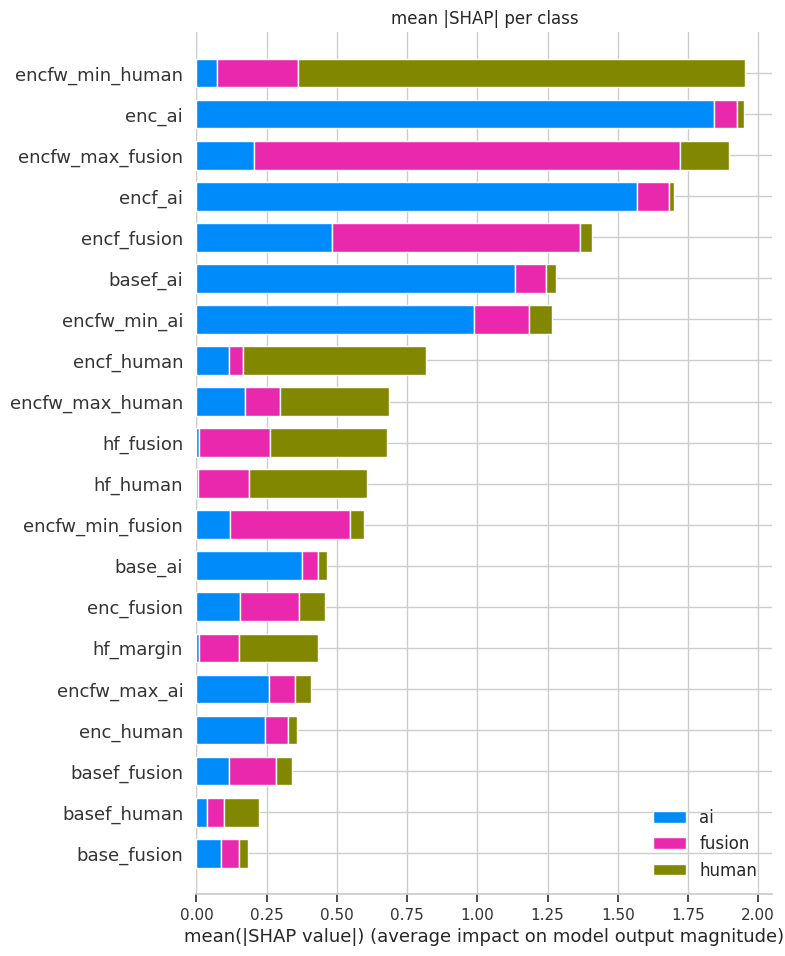

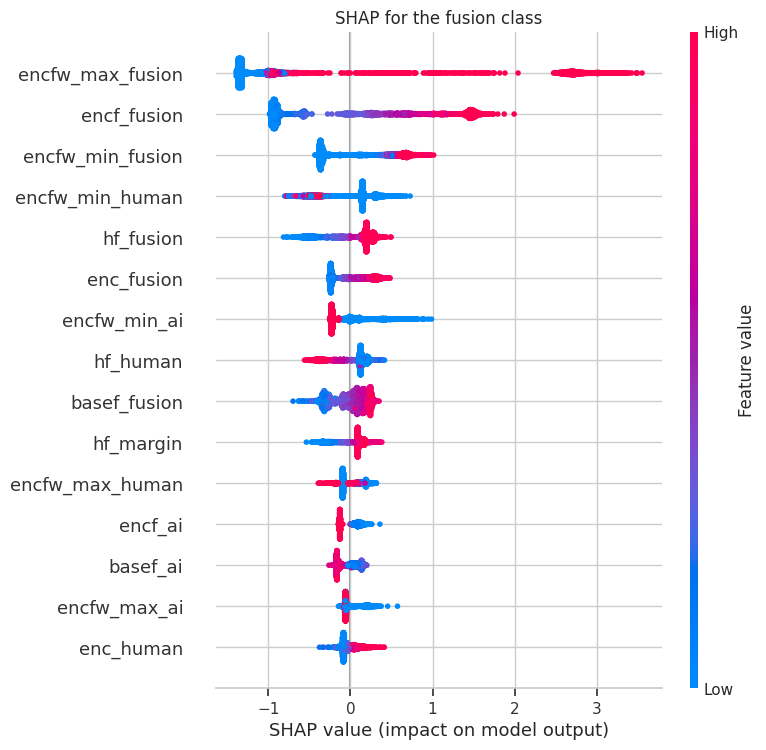

In [7]:
import shap
try:  # prefer the 04b stacker, fall back to 04
    st, X = joblib.load(find('stacker_04b.joblib')), pd.read_csv(find('stack_val_features_04b.csv'))
except FileNotFoundError:
    st, X = joblib.load(find('stacker.joblib')), pd.read_csv(find('stack_val_features.csv'))
X = X[st['cols']]
Xs = X.sample(min(3000, len(X)), random_state=SEED)
sv = shap.TreeExplainer(st['models'][0]).shap_values(Xs)
sv = [sv[:, :, k] for k in range(3)] if np.ndim(sv) == 3 else list(sv)
shap.summary_plot(sv, Xs, plot_type='bar', class_names=LABELS, show=False, max_display=20)
plt.title('mean |SHAP| per class'); plt.savefig(OUT / 'xai_shap_bar.png', dpi=120, bbox_inches='tight'); plt.show()
shap.summary_plot(sv[L2I['fusion']], Xs, show=False, max_display=15)
plt.title('SHAP for the fusion class'); plt.savefig(OUT / 'xai_shap_fusion.png', dpi=120, bbox_inches='tight'); plt.show()

## Conclusions

- **TF-IDF n-grams (baseline).** The strongest weights are mostly typography and fixed phrases, not topic words. *human* ← sentence-final quotes (`.'`, `.’`) and the German closing formula *„Vielen Dank“* / *„Danke“* of Bundestag speeches. *ai* ← curly apostrophes (`’s`, `n’t`, `’t`) and informal blog words (*let, just, gotta, omg, seriously*). *fusion* ← space before a quote (` '`, ` "`), ellipses (`..`, `...`), abbreviations (`U.`, `S.`) and chat-like phrases (*let me know (if)*, *let me*, *missing part*). The last group looks like leftovers of the LLM rewriting step rather than writing style, i.e. likely dataset artifacts that the models exploit.
- **Encoder token attributions (Integrated Gradients, first 256 tokens).** The fine-tuned mDeBERTa also leans on punctuation and quote characters: `“`, `(`, `"` push towards ai, `)` towards human, and `...` is the top token for fusion. German parliamentary forms of address (*Liebe*, *Damen*, *Herren*, *-innen*) push towards fusion: the openings of Bundestag speeches, a domain with many fusion texts. The human example shown is a misclassification (p(fusion) = 0.987), a typical human → fusion error. In the fusion example, an `[UNK]` token appears exactly where the text switches from the original speech to generic rewritten sentences, so the seam itself may carry a signal. Attributions cover only the first 256 tokens, so they cannot show whether the model focuses on rewritten parts later in a long text.
- **Stacker (SHAP, 04b).** The final model relies mostly on the **window-level statistics of the 03b encoder**: `encfw_min_human` dominates the human class and `encfw_max_fusion` the fusion class, ahead of the plain logits (`encf_*`, `enc_*`). A high fusion probability in *any* 512-token window means fusion, which matches the idea that fusion is a partial rewrite. This is the signal that chunk *averaging* dilutes (chunks < head+tail in 03/03b), and min/max over windows recovers it, which explains most of the jump from 0.93 to 0.97. The 03c specialist (`hf_*`) and the full TF-IDF model (`basef_ai`) come next. No LM or Binoculars feature appears in the top 20, consistent with E2b/E2c adding nothing over E2a.
- Caveat: SHAP is computed for the fold-0 stacker on 3k val rows, some of which that fold model was trained on. It explains what the model uses, not how well it generalizes.